# Probabilistic Email Threat Detection Using Maximum Entropy

This notebook applies a **Maximum Entropy (MaxEnt)** probabilistic classifier to a realistic cybersecurity NLP problem: classifying email/message text into **Ham**, **Phish**, or **Spam**.

In [2]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
    log_loss,
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment ready")

Environment ready


## 1. Stratified Train / Validation / Test Split

We use 70% training, 15% validation, and 15% testing.


In [4]:
data = pd.read_csv("archive/cleaned_email_data.csv")

if data.empty:
    print("Data is empty. Please check the file path and contents.")

In [5]:
X = data["clean_text"]
y = data["label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 195657
Validation: 41926
Test: 41927


In [6]:
y_train.value_counts(normalize=True).round(4)

label
Ham      0.4582
Spam     0.3885
Phish    0.1533
Name: proportion, dtype: float64

## 2. Text Representation — TF-IDF

In [7]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    max_features=75000,
    sublinear_tf=True,
    dtype=np.float32,
    strip_accents="unicode"
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

print("Train matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)
print("Test matrix:", X_test_tfidf.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

Train matrix: (195657, 75000)
Validation matrix: (41926, 75000)
Test matrix: (41927, 75000)
Vocabulary size: 75000


In [8]:
print(X_train_tfidf)

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 34860041 stored elements and shape (195657, 75000)>
  Coords	Values
  (0, 14298)	0.1866500973701477
  (0, 39208)	0.21022696793079376
  (0, 46687)	0.08734237402677536
  (0, 60454)	0.11436229199171066
  (0, 10037)	0.1600523144006729
  (0, 54193)	0.15558496117591858
  (0, 55470)	0.1291949599981308
  (0, 71133)	0.2593512535095215
  (0, 9332)	0.24935439229011536
  (0, 43588)	0.06350136548280716
  (0, 71096)	0.0995032787322998
  (0, 46533)	0.059764932841062546
  (0, 73910)	0.08480927348136902
  (0, 73512)	0.12299355864524841
  (0, 54183)	0.21905331313610077
  (0, 70907)	0.15863177180290222
  (0, 31680)	0.20260204374790192
  (0, 65939)	0.1014098972082138
  (0, 114)	0.10658042132854462
  (0, 6755)	0.08342349529266357
  (0, 555)	0.08608661592006683
  (0, 70)	0.13325712084770203
  (0, 68094)	0.17789411544799805
  (0, 24859)	0.15121488273143768
  (0, 67525)	0.09075893461704254
  :	:
  (195656, 17102)	0.11412917077541351
  (195656, 2620

## 3. Majority-Class Baseline

The baseline always predicts the most frequent class. A meaningful NLP model should outperform this simple strategy, especially on minority classes.

In [9]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_tfidf, y_train)
baseline_pred = baseline.predict(X_test_tfidf)

baseline_accuracy = accuracy_score(y_test, baseline_pred)
print("Majority baseline accuracy:", round(baseline_accuracy, 4))
print(classification_report(y_test, baseline_pred, zero_division=0))

Majority baseline accuracy: 0.4582
              precision    recall  f1-score   support

         Ham       0.46      1.00      0.63     19212
       Phish       0.00      0.00      0.00      6426
        Spam       0.00      0.00      0.00     16289

    accuracy                           0.46     41927
   macro avg       0.15      0.33      0.21     41927
weighted avg       0.21      0.46      0.29     41927



## 4. Initial MaxEnt Model

We use `LogisticRegression` with the `saga` solver, which is suitable for large sparse TF-IDF matrices. `class_weight="balanced"` gives additional importance to classes with fewer training examples.

In [10]:
maxent = LogisticRegression(
    C=1.0,
    solver="saga",
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)
maxent.fit(X_train_tfidf, y_train)

val_pred = maxent.predict(X_val_tfidf)
val_proba = maxent.predict_proba(X_val_tfidf)

Validation accuracy: 0.9734


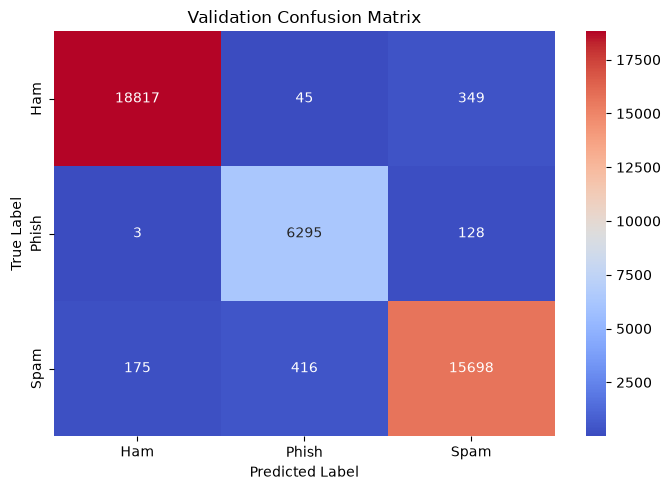

In [11]:
print("Validation accuracy:", round(accuracy_score(y_val, val_pred), 4))

labels = ["Ham", "Phish", "Spam"]

cm = confusion_matrix(y_val, val_pred, labels=labels)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="coolwarm",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()

## 5. Validation Metrics

We report accuracy, precision, recall, and F1-score. For the security objective, phishing recall is particularly important because a missed phishing email can be more costly than a false alarm.

In [12]:
vp, vr, vf, vs = precision_recall_fscore_support(
    y_val, val_pred, labels=["Ham", "Phish", "Spam"], zero_division=0
)
validation_results = pd.DataFrame({
    "class": ["Ham", "Phish", "Spam"],
    "precision": vp,
    "recall": vr,
    "f1": vf,
    "support": vs
})
display(validation_results.round(4))

,class,precision,recall,f1,support
0,Ham,0.9906,0.9795,0.9850,19211
1,Phish,0.9318,0.9796,0.9551,6426
2,Spam,0.9705,0.9637,0.9671,16289


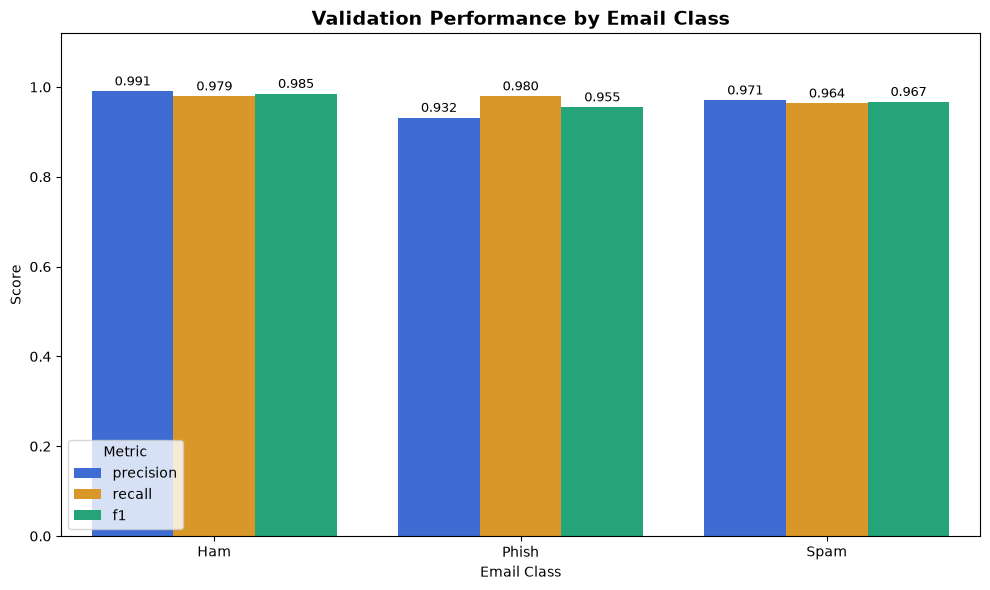

In [13]:
metrics = validation_results.melt(
    id_vars="class",
    value_vars=["precision", "recall", "f1"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=metrics,
    x="class",
    y="Score",
    hue="Metric",
    palette=["#2563EB", "#F59E0B", "#10B981"]
)

ax.bar_label(ax.containers[0], fmt="%.3f", padding=2, fontsize=9)
ax.bar_label(ax.containers[1], fmt="%.3f", padding=2, fontsize=9)
ax.bar_label(ax.containers[2], fmt="%.3f", padding=2, fontsize=9)

plt.title("Validation Performance by Email Class", fontsize=14, weight="bold")
plt.xlabel("Email Class")
plt.ylabel("Score")
plt.ylim(0, 1.12)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

## 6. Hyperparameter Experiment — Regularization

In [14]:
C_values = [0.25, 0.5, 1.0, 2.0, 4.0]
rows = []

for C in C_values:
    model = LogisticRegression(
        C=C, solver="saga", max_iter=1000,
        class_weight="balanced", random_state=RANDOM_STATE
    )
    model.fit(X_train_tfidf, y_train)
    pred = model.predict(X_val_tfidf)
    proba = model.predict_proba(X_val_tfidf)

    macro_f1 = precision_recall_fscore_support(
        y_val, pred, average="macro", zero_division=0
    )[2]
    phish_recall = precision_recall_fscore_support(
        y_val, pred, labels=["Phish"], average=None, zero_division=0
    )[1][0]

    rows.append({
        "C": C,
        "accuracy": accuracy_score(y_val, pred),
        "macro_f1": macro_f1,
        "phish_recall": phish_recall,
        "log_loss": log_loss(y_val, proba, labels=model.classes_)
    })

tuning_results = pd.DataFrame(rows)
display(tuning_results.round(4))

best_row = tuning_results.sort_values(["macro_f1", "phish_recall"], ascending=False).iloc[0]
BEST_C = float(best_row["C"])
print("Selected C:", BEST_C)

,C,accuracy,macro_f1,phish_recall,log_loss
0,0.25,0.9660,0.9613,0.9812,0.1388
1,0.50,0.9699,0.9653,0.9798,0.1123
2,1.00,0.9734,0.9691,0.9796,0.0926
3,2.00,0.9758,0.9714,0.9781,0.0785
4,4.00,0.9778,0.9735,0.9754,0.0681


Selected C: 4.0


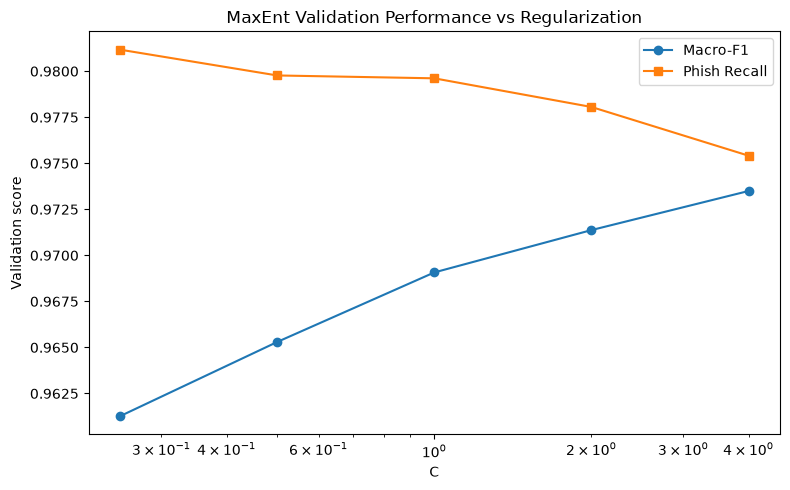

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(tuning_results["C"], tuning_results["macro_f1"], marker="o", label="Macro-F1")
plt.plot(tuning_results["C"], tuning_results["phish_recall"], marker="s", label="Phish Recall")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Validation score")
plt.title("MaxEnt Validation Performance vs Regularization")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Final Model Training

In [16]:
# Retraining the model on the combined training and validation sets with the best C value
X_trainval = pd.concat([X_train, X_val])
y_trainval = pd.concat([y_train, y_val])

final_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2), min_df=2, max_df=0.98,
    max_features=75000, sublinear_tf=True,
    dtype=np.float32, strip_accents="unicode"
)

X_trainval_tfidf = final_vectorizer.fit_transform(X_trainval)
X_test_final_tfidf = final_vectorizer.transform(X_test)

final_model = LogisticRegression(
    C=BEST_C, solver="saga", max_iter=1000,
    class_weight="balanced", random_state=RANDOM_STATE
)
final_model.fit(X_trainval_tfidf, y_trainval)

test_pred = final_model.predict(X_test_final_tfidf)
test_proba = final_model.predict_proba(X_test_final_tfidf)

print("Final train matrix:", X_trainval_tfidf.shape)
print("Final test matrix:", X_test_final_tfidf.shape)

Final train matrix: (237583, 75000)
Final test matrix: (41927, 75000)


## 8. Final Test Results

The test set is the final unbiased evaluation of the chosen model. These are the numbers that should appear in the presentation.

In [17]:
test_accuracy = accuracy_score(y_test, test_pred)
tp, tr, tf, ts = precision_recall_fscore_support(
    y_test, test_pred, labels=["Ham", "Phish", "Spam"], zero_division=0
)

final_results = pd.DataFrame({
    "class": ["Ham", "Phish", "Spam"],
    "precision": tp,
    "recall": tr,
    "f1": tf,
    "support": ts
})

macro_f1 = final_results["f1"].mean()
weighted_f1 = precision_recall_fscore_support(
    y_test, test_pred, average="weighted", zero_division=0
)[2]

print("Test Accuracy:", round(test_accuracy, 4))
print("Macro-F1:", round(macro_f1, 4))
print("Weighted-F1:", round(weighted_f1, 4))
display(final_results.round(4))

Test Accuracy: 0.9787
Macro-F1: 0.975
Weighted-F1: 0.9788


,class,precision,recall,f1,support
0,Ham,0.9925,0.9845,0.9885,19212
1,Phish,0.9514,0.9746,0.9629,6426
2,Spam,0.9736,0.9735,0.9735,16289


## 9. Baseline vs MaxEnt

We compare the final classifier with the majority baseline. The important question is whether MaxEnt provides meaningful improvement rather than merely achieving a high raw accuracy.

In [18]:
baseline_macro_f1 = precision_recall_fscore_support(
    y_test, baseline_pred, average="macro", zero_division=0
)[2]
baseline_weighted_f1 = precision_recall_fscore_support(
    y_test, baseline_pred, average="weighted", zero_division=0
)[2]

comparison = pd.DataFrame({
    "model": ["Majority baseline", "Maximum Entropy"],
    "accuracy": [baseline_accuracy, test_accuracy],
    "macro_f1": [baseline_macro_f1, macro_f1],
    "weighted_f1": [baseline_weighted_f1, weighted_f1]
})
display(comparison.round(4))

,model,accuracy,macro_f1,weighted_f1
0,Majority baseline,0.4582,0.2095,0.2880
1,Maximum Entropy,0.9787,0.9750,0.9788


## 10. Confusion Matrix

The most security-sensitive error is **Phish → Ham**, because a phishing message is incorrectly considered legitimate. **Ham → Phish** represents a false alarm, while **Phish → Spam** means the system recognizes the message as unwanted but fails to identify it specifically as phishing.

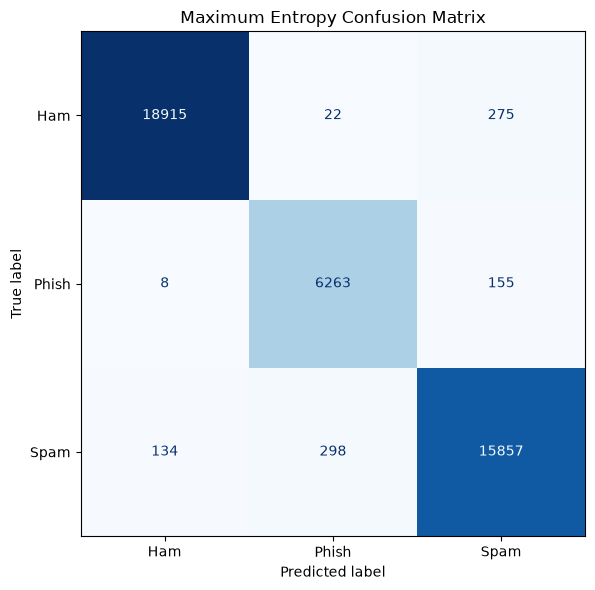

In [19]:
cm = confusion_matrix(y_test, test_pred, labels=["Ham", "Phish", "Spam"])
disp = ConfusionMatrixDisplay(cm, display_labels=["Ham", "Phish", "Spam"])
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, values_format="d", cmap="Blues", colorbar=False)
ax.set_title("Maximum Entropy Confusion Matrix")
plt.tight_layout()
plt.show()

## 11. Phishing-Specific Metrics

Because phishing is the primary security target, we report its precision, recall, and F1 separately.

- **Precision:** among emails predicted as phishing, how many are actually phishing?
- **Recall:** among actual phishing emails, how many are detected?
- **F1:** balance between precision and recall.

In [20]:
pp, pr, pf, ps = precision_recall_fscore_support(
    y_test, test_pred, labels=["Phish"], average=None, zero_division=0
)
print("Phishing precision:", round(pp[0], 4))
print("Phishing recall:", round(pr[0], 4))
print("Phishing F1:", round(pf[0], 4))
print("Phishing support:", ps[0])

Phishing precision: 0.9514
Phishing recall: 0.9746
Phishing F1: 0.9629
Phishing support: 6426


## 12. Prediction Inspection

We create a table containing the message, actual label, predicted label, and all class probabilities. This provides concrete examples for qualitative interpretation.

In [28]:
prediction_view = pd.DataFrame({
    "text": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": test_pred,
    "P(Ham)": test_proba[:, list(final_model.classes_).index("Ham")],
    "P(Phish)": test_proba[:, list(final_model.classes_).index("Phish")],
    "P(Spam)": test_proba[:, list(final_model.classes_).index("Spam")]
})
prediction_view["confidence"] = test_proba.max(axis=1)
display(prediction_view.head(15).round(4))

,text,actual,predicted,P(Ham),P(Phish),P(Spam),confidence
0,kevin discussed today since dont know anymore ...,Ham,Ham,0.9999,0.0000,0.0001,0.9999
1,khaled276 khaledahmedpharmbsuedueg outlook exc...,Phish,Phish,0.0082,0.9700,0.0218,0.9700
2,fränzi korner oikostat ch writes sorry for not...,Ham,Ham,0.9977,0.0000,0.0023,0.9977
3,veterans holiday building hours monday escapen...,Ham,Ham,0.9910,0.0000,0.0090,0.9910
4,legislating unconditional divests returner det...,Spam,Spam,0.0130,0.0000,0.9870,0.9870
5,advertisement iit demokritos gr has qualified ...,Spam,Spam,0.0002,0.0000,0.9998,0.9998
6,drop box servicefilesafecom dear josemonkeyorg...,Phish,Phish,0.0154,0.9836,0.0010,0.9836
7,escapenumber cescapenumber descapenumber besca...,Spam,Spam,0.0030,0.0002,0.9968,0.9968
8,dear customer this is the letter from the cana...,Spam,Spam,0.0009,0.0001,0.9990,0.9990
9,barrister stephen kwesi kwesi consultants accr...,Spam,Spam,0.0091,0.0000,0.9909,0.9909


## 13. Confidence Distribution

The maximum class probability is used as a simple confidence measure. Low-confidence messages are candidates for additional analysis or human review in a real system.

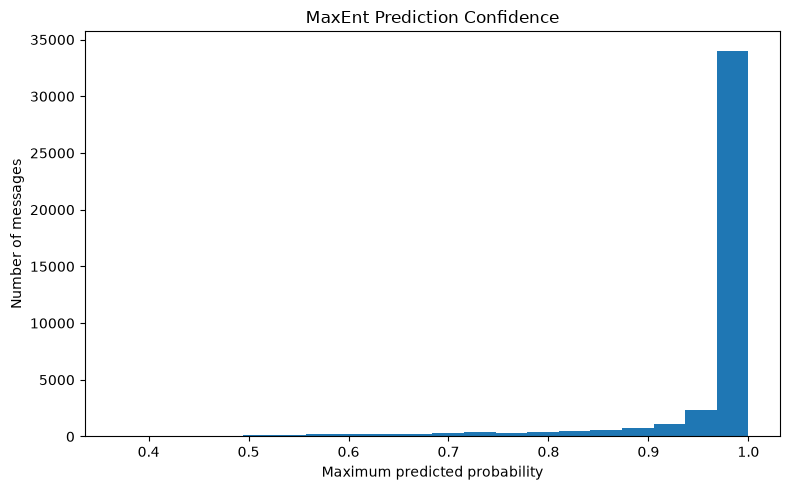

In [29]:
plt.figure(figsize=(8, 5))
plt.hist(prediction_view["confidence"], bins=20)
plt.xlabel("Maximum predicted probability")
plt.ylabel("Number of messages")
plt.title("MaxEnt Prediction Confidence")
plt.tight_layout()
plt.show()

## 14. Important Features

The coefficients of the MaxEnt model show which TF-IDF features are most strongly associated with each class.

These are statistical associations, not hard rules. A word associated with phishing does not automatically make every message containing that word malicious.

In [24]:
feature_names = np.array(final_vectorizer.get_feature_names_out())

def top_features(model, class_name, n=20):
    idx = list(model.classes_).index(class_name)
    coef = model.coef_[idx]
    top = np.argsort(coef)[-n:][::-1]
    return pd.DataFrame({"feature": feature_names[top], "coefficient": coef[top]})

for cls in ["Ham", "Phish", "Spam"]:
    print("\nTop features for", cls)
    display(top_features(final_model, cls, 20).round(4))


Top features for Ham


,feature,coefficient
0,escapenumber,21.228701
1,enron,12.858100
2,thanks,9.700900
3,subject,9.262800
4,the,8.524000
5,to,8.372600
6,escapenumber escapenumber,8.317000
7,wrote,7.372800
8,edu,7.251700
9,for,7.002000



Top features for Phish


,feature,coefficient
0,2008,9.1852
1,aug,8.2760
2,aug 2008,8.1280
3,nan,6.8204
4,fw,6.4570
5,0000,6.1632
6,2005,6.1198
7,software,6.1014
8,thu,5.6416
9,message subject,5.4295



Top features for Spam


,feature,coefficient
0,escapenumber,20.737301
1,escapelong,11.092900
2,no,9.494900
3,your,8.215100
4,here,7.167400
5,our,6.656100
6,and,6.575900
7,enron com,6.501900
8,subject,6.420600
9,more,6.176200


## 15. Error Analysis

Metrics alone do not explain why predictions fail. We inspect representative errors and focus on security-relevant confusion patterns.

In [30]:
errors = prediction_view[prediction_view["actual"] != prediction_view["predicted"]].copy()
print("Total test errors:", len(errors))
print("Error rate:", round(len(errors) / len(prediction_view), 4))
display(errors["actual"].value_counts().rename("errors_by_true_class"))

Total test errors: 892
Error rate: 0.0213


actual
Spam     432
Ham      297
Phish    163
Name: errors_by_true_class, dtype: int64

In [31]:
phish_as_ham = prediction_view[(prediction_view["actual"] == "Phish") & (prediction_view["predicted"] == "Ham")].sort_values("confidence", ascending=False)
print("Phish -> Ham errors:", len(phish_as_ham))
display(phish_as_ham[["actual", "predicted", "confidence", "P(Ham)", "P(Phish)", "P(Spam)", "text"]].head(15).round(4))

Phish -> Ham errors: 8


,actual,predicted,confidence,P(Ham),P(Phish),P(Spam),text
36121,Phish,Ham,0.7588,0.7588,0.1983,0.0428,document please read attached file
30867,Phish,Ham,0.6255,0.6255,0.1021,0.2724,kluwer alerts springer alerts dear kluwer aler...
30716,Phish,Ham,0.5243,0.5243,0.1893,0.2864,important requested file
23742,Phish,Ham,0.5145,0.5145,0.3992,0.0863,welcome jokes internet magazine cn 80924609220...
38466,Phish,Ham,0.5016,0.5016,0.1930,0.3054,junk mail books linguists plurabelle books new...
5002,Phish,Ham,0.4842,0.4842,0.4168,0.0990,dumb blonde office exec interviewing blonde as...
17581,Phish,Ham,0.4830,0.4830,0.2536,0.2635,like saltwater aquariums horizon publishing wo...
22663,Phish,Ham,0.3678,0.3678,0.2871,0.3451,risk kiosk pg lnbcer hey guy yome biot insted ...


In [32]:
ham_as_phish = prediction_view[(prediction_view["actual"] == "Ham") & (prediction_view["predicted"] == "Phish")].sort_values("confidence", ascending=False)
print("Ham -> Phish errors:", len(ham_as_phish))
display(ham_as_phish[["actual", "predicted", "confidence", "P(Ham)", "P(Phish)", "P(Spam)", "text"]].head(15).round(4))

Ham -> Phish errors: 22


,actual,predicted,confidence,P(Ham),P(Phish),P(Spam),text
5230,Ham,Phish,0.8783,0.0970,0.8783,0.0246,postfix program host exseamxescapenumber concu...
17741,Ham,Phish,0.8170,0.0019,0.8170,0.1811,spam
16985,Ham,Phish,0.7327,0.1941,0.7327,0.0732,subject autumn school gldv gesellschaft fuer l...
18102,Ham,Phish,0.6890,0.2271,0.6890,0.0839,whats worse pyromaniac blazer barber seville s...
17618,Ham,Phish,0.6395,0.3080,0.6395,0.0525,kay deepest sympathies loss father thoughts fa...
29451,Ham,Phish,0.6289,0.1463,0.6289,0.2248,subject ii jornadas de linguistica aborigen ii...
16838,Ham,Phish,0.6065,0.0310,0.6065,0.3625,dear applicant time post offer however continu...
28204,Ham,Phish,0.6007,0.2409,0.6007,0.1585,subject 4 internationale arbeitstagung f r com...
4839,Ham,Phish,0.5950,0.3056,0.5950,0.0993,huntsville / woodlands / conroe 11500 by 8 day...
35688,Ham,Phish,0.5912,0.3818,0.5912,0.0269,thank submitting resume open link financial in...


In [33]:
phish_as_spam = prediction_view[(prediction_view["actual"] == "Phish") & (prediction_view["predicted"] == "Spam")].sort_values("confidence", ascending=False)
print("Phish -> Spam errors:", len(phish_as_spam))
display(phish_as_spam[["actual", "predicted", "confidence", "P(Ham)", "P(Phish)", "P(Spam)", "text"]].head(15).round(4))

Phish -> Spam errors: 155


,actual,predicted,confidence,P(Ham),P(Phish),P(Spam),text
19175,Phish,Spam,0.9494,0.0102,0.0404,0.9494,remember tv spot see true anal stories instant...
16283,Phish,Spam,0.9367,0.0048,0.0585,0.9367,hello washing instructions adio
34242,Phish,Spam,0.9278,0.0092,0.0630,0.9278,katherine ham vya 431 kelli ballard http berea...
1433,Phish,Spam,0.9267,0.0003,0.0731,0.9267,microsoft windows xp professional sp 2 1 cd 50...
27205,Phish,Spam,0.9128,0.0002,0.0870,0.9128,customer friendly onlinne meds solution bolton...
3908,Phish,Spam,0.9120,0.0007,0.0873,0.9120,cum eaters chat horny babes online http ndj so...
33502,Phish,Spam,0.8992,0.0009,0.0999,0.8992,older horny babes see sandra favourite milf re...
39739,Phish,Spam,0.8927,0.0159,0.0914,0.8927,find everything surfing www surferguy ca atlan...
23483,Phish,Spam,0.8895,0.0002,0.1102,0.8895,wow cant beleive real rolex hello thank expres...
30844,Phish,Spam,0.8891,0.0255,0.0854,0.8891,carry bawek arly buczek


## 16. Model Saving

The trained model and TF-IDF vectorizer can be saved with `joblib` for later inference without retraining.

In [36]:
import joblib, json

joblib.dump(final_model, "model/maxent_phishing_model.joblib")
joblib.dump(final_vectorizer, "model/tfidf_vectorizer.joblib")
print("Saved model and vectorizer.")

Saved model and vectorizer.


## 17. Final Conclusion

On the held-out test set, the model achieved 97.87% accuracy, 0.9750 macro-F1, and 0.9788 weighted-F1, substantially outperforming the majority-class baseline (45.82% accuracy; 0.2095 macro-F1). For phishing, precision was 95.14%, recall was 97.46%, and F1 was 0.9629 across 6,426 test messages.

These results show strong performance on this dataset, but they do not guarantee reliable detection on new or changing email data. Error analysis found 8 phishing messages predicted as Ham and 155 predicted as Spam. The first type can make a phishing message appear legitimate; the second recognizes it as unwanted but misses its phishing label. The model also relies on message text alone, and the reported results are specific to this dataset and split.

Confidence scores should not be treated as calibrated risk estimates. A 0.5 review threshold is only a possible starting point, not a validated policy; it should be selected using validation data, calibration checks, and the relative cost of missed phishing versus false alarms.

Overall, the MaxEnt model is a promising educational prototype and a useful baseline for further work, but it should not be used as a standalone production security control. Future work should test on newer and more diverse data, assess calibration and threshold trade-offs, and consider adding non-text signals.